# 04 XGBoost



## Setup (Imports and Loading Data)

In [ ]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append('../src')

from load_clean_data import load_clean_data
from backtest import get_cutoffs, split_data_by_cutoff, run_backtest
from baselines import add_window_avg_baseline, add_all_baselines
from evaluation import evaluate_forecast, score_forecasts
from features import build_features, FEATURE_COLUMNS
from models import add_xgb_forecast

In [2]:
df = load_clean_data()
df_with_features = build_features(df)

## Train Test Split

In [3]:
train, test = split_data_by_cutoff(df_with_features, '2015-02-02', 7)

## Run XGB (One Cutoff)

In [ ]:
FORECAST = False

if FORECAST:
    results = add_xgb_forecast(train, test, '2015-02-02')

In [5]:
print(len(results))
print(results['xgboost_forecast'].describe())

7805
count     7805.000000
mean      6810.472168
std       3945.342041
min          0.000000
25%       4929.944336
50%       6953.083008
75%       9048.419922
max      27231.585938
Name: xgboost_forecast, dtype: float64


### Compare against baselines

In [6]:
results = add_all_baselines(train, results, '2015-02-02')

scores = score_forecasts(results, ['naive_baseline', 'avg_28d_baseline', 'avg_all_baseline', 'xgboost_forecast'])

In [7]:
scores.sort_values(by='WAPE').style.hide(axis='index').format({ 'WAPE': '{:.2f}%' }, precision=2)

Model,RMSE,MAE,WAPE
xgboost_forecast,1053.18,688.49,10.63%
avg_28d_baseline,1128.94,711.88,10.99%
naive_baseline,1098.63,711.96,10.99%
avg_all_baseline,1261.37,887.79,13.71%


## Run XGB (All Cutoffs)

In [8]:
def forecast_all(train, test, cutoff):
    with_baseleines = add_all_baselines(train, test, cutoff)
    with_xgb = add_xgb_forecast(train, with_baseleines, cutoff)
    return with_xgb

In [ ]:
FORECAST = False

if FORECAST:
    cutoffs = get_cutoffs(df['Date'].max(), 7)
    bt = run_backtest(df_with_features, cutoffs, 7, forecast_all)

    bt.to_csv('../results/xgb_baselines_backtest.csv', index=False)

In [15]:
forecasts = ['naive_baseline', 'avg_28d_baseline', 'avg_all_baseline', 'xgboost_forecast']

scores = score_forecasts(bt, forecasts)
scores.to_csv('../results/xgb_scores.csv', index=False)

scores.sort_values(by='WAPE').style.hide(axis='index').format({ 'WAPE': '{:.2f}%' }, precision=2)

Model,RMSE,MAE,WAPE
xgboost_forecast,1001.30,604.95,10.33%
avg_all_baseline,2029.48,1261.49,21.53%
avg_28d_baseline,2127.55,1326.10,22.63%
naive_baseline,3206.68,2112.59,36.06%


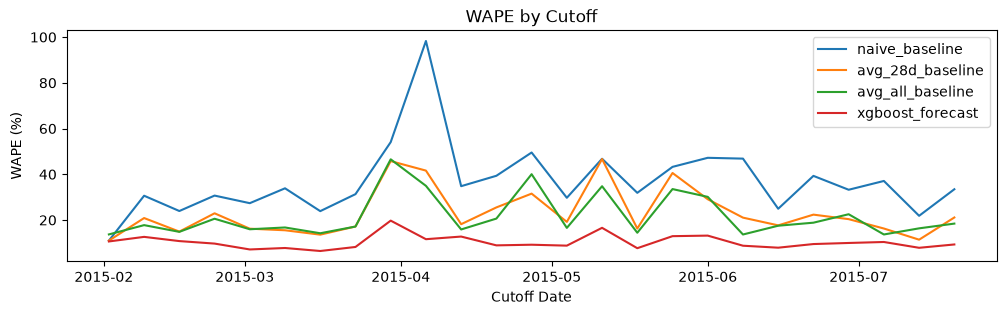

In [17]:
scores_by_cutoff = score_forecasts(bt, forecasts, by='cutoff')

pivotted = scores_by_cutoff.pivot(index='cutoff', columns='Model', values='WAPE')

plt.figure(figsize=(12, 3))

for model in forecasts:
    plt.plot(pivotted.index, pivotted[model], label=model)

plt.title('WAPE by Cutoff')
plt.xlabel('Cutoff Date')
plt.ylabel('WAPE (%)')
plt.legend()

plt.show()

## Feature Importance

In [ ]:
import xgboost as xgb
from models import XGB_PARAMS

train, test = split_data_by_cutoff(df_with_features, '2015-07-20', 7)

model = xgb.XGBRegressor(**XGB_PARAMS)

model.fit(train[FEATURE_COLUMNS], train['Sales'])

feature_importances = pd.Series(model.feature_importances_, index=FEATURE_COLUMNS).sort_values()

feature_importances.plot(kind='barh', figsize=(8, 6), title='Feature Importances')